# Mathematics prediction with Ridge regression

Author: Annie Rajesh Vadakara. Code developed with AI assistance and checked by execution. 

Uses the shared clean PISA 2022 data from Ahmed's EDA. The main experiment uses all 17 agreed predictors and their missing indicators. Additional predictor-set comparisons are exploratory and do not replace the team's shared ablation analysis.

Protocol used: existing five school folds, SENWT for training and every metric, all ten mathematics plausible values, median imputation and RobustScaler inside a pipeline. Reading, science, IDs, quality flags and system labels are excluded from predictors. No new split or cleaning rules are introduced.

Ridge retains the four family measures because L2 regularisation handles coefficient dependence. The ESCS-only instruction applies explicitly to logistic regression and naive Bayes. Individual Ridge coefficients are not interpreted as independent effects.

Sources: [OECD PISA database](https://www.oecd.org/en/data/datasets/pisa-2022-database.html), [OECD analysis guidance](https://www.oecd.org/en/about/programmes/pisa/how-to-prepare-and-analyse-the-pisa-database.html), [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).

Run in order using scikit-learn 1.6 or later. Results display here without exporting CSV files. Use a Python environment that has pandas, NumPy, PyArrow, Matplotlib and scikit-learn installed.

## 1. Load the shared files

Run this notebook from 03_baselines in a checkout based on Ahmed-EDA. As in the team slides, the three prepared inputs are loaded from ../data/clean using relative paths. The files already exist in that branch, so cleaning and EDA do not need rerunning unless their rules change. No data are downloaded from GitHub during execution.

**In brief:** We load the same prepared files used by the team so that model results are comparable. The cleaning and EDA are already complete.

In [1]:
# Import the packages used for data preparation, model training and evaluation.
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn import set_config
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler

# Run from 03_baselines and load the files already supplied by Ahmed's branch.
# There is no need to rerun the cleaning or EDA notebooks.
df = pd.read_parquet("../data/clean/pisa6_clean.parquet")
with open("../data/clean/columns.json", encoding="utf-8") as file:
    roles = json.load(file)
folds = pd.read_csv("../data/clean/folds.csv")
print("Python:", platform.python_version(), "scikit-learn:", sklearn.__version__)
print("Students and columns:", df.shape)
display(df[["CNT", "CNTSCHID", "CNTSTUID", "PV1MATH", "SENWT"]].head())

Python: 3.14.6 scikit-learn: 1.9.0
Students and columns: (61775, 158)


,CNT,CNTSCHID,CNTSTUID,PV1MATH,SENWT
0,PSE,27500099,27500001,419.291,0.09688
1,PSE,27500050,27500002,300.023,0.73159
2,PSE,27500157,27500003,292.200,0.61503
3,PSE,27500213,27500004,285.349,0.76630
4,PSE,27500038,27500005,398.140,0.35956


## 2. Check targets, weights and existing school folds

Every student receives the assignment saved for their system and school. Assertions stop execution if records duplicate, targets are unavailable or a school crosses folds. SENWT remains the weight for pooled and system-specific metrics, as required by the slides.

**In brief:** These checks confirm that the inputs are usable and students from one school stay together. This prevents the model from being evaluated on other students from a school it trained on.

In [2]:
# Check source identifiers before attaching the saved fold assignments.
keys = ["CNT", "CNTSCHID"]
assert not df.duplicated(["CNT", "CNTSTUID"]).any()
assert not folds.duplicated(keys).any()
assert df[keys + ["CNTSTUID"]].notna().all().all()
original_rows = len(df)
df = df.merge(folds[keys + ["fold"]], on=keys, how="left", validate="many_to_one", sort=False)
assert len(df) == original_rows
assert df["fold"].notna().all()
assert set(df["fold"].unique()) == set(range(5))
assert df.groupby(keys)["fold"].nunique().eq(1).all()

# Use the targets supplied in the shared column definitions.
targets = roles["targets"]["regression"]
assert len(targets) == 10
assert np.isfinite(df[targets].to_numpy()).all()
assert np.isfinite(df["SENWT"]).all() and df["SENWT"].gt(0).all()
weight_snapshot = df["SENWT"].copy()

# Show the actual school and student coverage of the shared evaluation folds.
fold_audit = df.groupby("fold").agg(students=("CNTSTUID", "size"), schools=("CNTSCHID", "nunique"))
display(fold_audit)
display(df.groupby("CNT")["SENWT"].sum().rename("senate_weight_total").round(3))

,students,schools
fold,,
0,12340,397
1,12330,396
2,12365,394
3,12361,394
4,12379,392


CNT
ARE    4999.993
JOR    5000.000
MAR    5000.001
PSE    5000.000
QAT    4999.999
SAU    5000.000
Name: senate_weight_total, dtype: float64

## 3. Specify predictor sets and the pipeline

All 17 is the primary specification. Three additional specifications address the earlier family, attitudes and school-organisation comparison. Each set includes only its own precomputed missing indicators.

Median imputation and robust scaling learn from training records only. No percentile clipping is introduced because the slides do not require it and no shared clipping helper is present. Binary private-school status and the existing log school size are used exactly as supplied.

**In brief:** The pipeline fills missing values and puts predictors on comparable scales using training data only. The smaller predictor sets help us examine what attitudes and school organisation add beyond family background.

In [3]:
# Read predictor names from the shared definitions rather than retyping the 17 variables.
groups = roles["feature_groups"]
configurations = {
    "Family": ["family"],
    "Family + attitudes": ["family", "maths_attitudes"],
    "Family + school organisation": ["family", "school_org"],
    "All 17": list(groups)
}
feature_sets = {}
for name, selected_groups in configurations.items():
    predictors = [column for group in selected_groups for column in groups[group]]
    indicators = [column for group in selected_groups for column in roles["missing_indicators"][group]]
    feature_sets[name] = predictors + indicators
    assert set(feature_sets[name]).issubset(df.columns)
    assert not set(feature_sets[name]) & set(roles["ids"] + targets + list(roles["targets"]["classification"]))
assert len([column for group in groups.values() for column in group]) == 17
assert not any(column.startswith(("PV", "W_FST", "BELOW_L2")) for columns in feature_sets.values() for column in columns)
display(pd.Series({name: len(columns) for name, columns in feature_sets.items()}, name="predictors_including_missing_flags"))

# Route training and validation weights through scikit-learn's standard interfaces.
set_config(enable_metadata_routing=True)
ridge = Ridge(solver="cholesky").set_fit_request(sample_weight=True)
pipeline = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), RobustScaler(), ridge)
weighted_mse = make_scorer(mean_squared_error, greater_is_better=False).set_score_request(sample_weight=True)
alpha_grid = np.logspace(-2, 4, 7)
print("Candidate alpha values:", alpha_grid)

# Standard metrics can return a separate result for each of the ten target columns.
metrics = {"RMSE": root_mean_squared_error, "MAE": mean_absolute_error, "R2": r2_score}

Candidate alpha values: [1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04]


Family                           8
Family + attitudes              14
Family + school organisation    16
All 17                          34
Name: predictors_including_missing_flags, dtype: int64

## 4. Tune on PV1 inside each outer training partition

The saved five folds remain the outer evaluation. For each excluded fold, the four remaining saved folds provide inner validation. GridSearchCV selects alpha using weighted validation MSE on PV1 only. That alpha is then fixed for all ten PVs in that outer fold. No held-out school's outcome enters tuning.

Training weights are divided by the outer training mean to keep the regularisation scale comparable across folds. This changes their overall scale, not their relative contribution. Scoring uses SENWT.

Ridge fits all ten target columns in one native multioutput call. This solves ten independent regressions with the same alpha and preprocessing. It does not average PVs or share fitted coefficients across outcomes.

**In brief:** We choose the strength of regularisation using inner validation, then test on separate schools. The ten plausible values remain separate prediction targets.

In [4]:
# Allocate one out-of-fold prediction for every student, model and plausible value.
predictions = {name: np.full((len(df), len(targets)), np.nan) for name in feature_sets}
predictions["Mean baseline"] = np.full((len(df), len(targets)), np.nan)
visits = np.zeros(len(df), dtype=int)
tuning_rows = []
alpha_search_rows = []
fold_metric_rows = []

for outer_fold in sorted(df["fold"].unique()):
    train = df["fold"].ne(outer_fold).to_numpy()
    test = ~train
    train_school_keys = pd.MultiIndex.from_frame(df.loc[train, keys])
    test_school_keys = pd.MultiIndex.from_frame(df.loc[test, keys])
    assert not train_school_keys.isin(test_school_keys).any()
    visits[test] += 1
    training_weights = df.loc[train, "SENWT"] / df.loc[train, "SENWT"].mean()
    test_weights = df.loc[test, "SENWT"]
    inner_cv = PredefinedSplit(df.loc[train, "fold"].to_numpy())

    for name, columns in feature_sets.items():
        # Tune only on the outer training data and let the pipeline learn within each inner fold.
        search = GridSearchCV(pipeline, {"ridge__alpha": alpha_grid}, scoring=weighted_mse,
                              cv=inner_cv, refit=True, return_train_score=True, n_jobs=1, error_score="raise")
        search.fit(df.loc[train, columns], df.loc[train, targets[0]], sample_weight=training_weights)
        # Retain the package's training and validation scores for the course parameter study.
        alpha_scores = pd.DataFrame(search.cv_results_)[["param_ridge__alpha", "mean_train_score", "mean_test_score"]]
        alpha_search_rows.append(alpha_scores.assign(configuration=name, outer_fold=int(outer_fold)))
        tuning_rows.append({"configuration": name, "outer_fold": int(outer_fold),
                            "alpha": search.best_params_["ridge__alpha"],
                            "inner_PV1_RMSE": np.sqrt(-search.best_score_)})
        # Ridge supports multiple targets and solves the same independent regression for each PV.
        model = clone(search.best_estimator_)
        model.fit(df.loc[train, columns], df.loc[train, targets], sample_weight=training_weights)
        predicted = model.predict(df.loc[test, columns])
        predictions[name][test] = predicted
        fold_scores = pd.DataFrame({metric: score(df.loc[test, targets], predicted,
            sample_weight=test_weights, multioutput="raw_values") for metric, score in metrics.items()})
        fold_metric_rows.append(fold_scores.assign(configuration=name, fold=int(outer_fold), PV=targets))

    # DummyRegressor also supports all ten independent weighted-mean targets in one call.
    baseline = DummyRegressor(strategy="mean")
    baseline.fit(df.loc[train, ["fold"]], df.loc[train, targets], sample_weight=training_weights)
    predictions["Mean baseline"][test] = baseline.predict(df.loc[test, ["fold"]])
    print("Completed outer fold", int(outer_fold))

assert np.all(visits == 1)
assert all(np.isfinite(values).all() for values in predictions.values())
pd.testing.assert_series_equal(df["SENWT"], weight_snapshot)
tuning_results = pd.DataFrame(tuning_rows)
alpha_search_results = pd.concat(alpha_search_rows, ignore_index=True)
fold_metrics = pd.concat(fold_metric_rows, ignore_index=True)
display(tuning_results)

Completed outer fold 0
Completed outer fold 1
Completed outer fold 2
Completed outer fold 3
Completed outer fold 4


,configuration,outer_fold,alpha,inner_PV1_RMSE
0,Family,0,10.00,72.629625
1,Family + attitudes,0,10.00,69.045659
2,Family + school organisation,0,100.00,68.584230
3,All 17,0,0.01,64.405097
4,Family,1,10.00,73.160901
5,Family + attitudes,1,10.00,69.461376
6,Family + school organisation,1,100.00,68.856849
7,All 17,1,10.00,64.636994
8,Family,2,10.00,73.392566
9,Family + attitudes,2,10.00,69.820680


## 5. Weighted out-of-fold performance across all ten PVs

Each student's prediction comes from a model that excluded their school. Compute metrics separately for each PV before averaging the metrics. Do not average PV scores to create an individual target.

The headline pooled result is calculated on all out-of-fold predictions with SENWT. It is not an unweighted average of fold scores. Per-system metrics use the same weights and the same pooled-trained model. This tests new schools within the represented systems, not transfer to an unseen system.

**In brief:** These scores measure how well the model predicts students from excluded schools. RMSE highlights larger mistakes, MAE gives average absolute error in score points, and R² provides context relative to outcome variation.

In [5]:
metric_rows = []
for name, predicted in predictions.items():
    for system in ["Pooled"] + sorted(df["CNT"].unique()):
        selected = np.ones(len(df), dtype=bool) if system == "Pooled" else df["CNT"].eq(system).to_numpy()
        weights = df.loc[selected, "SENWT"]
        # Evaluate every PV separately through the metrics' built-in multioutput support.
        scores = pd.DataFrame({metric: score(df.loc[selected, targets], predicted[selected],
            sample_weight=weights, multioutput="raw_values") for metric, score in metrics.items()})
        metric_rows.append(scores.assign(configuration=name, system=system, PV=targets))
metrics_by_pv = pd.concat(metric_rows, ignore_index=True)
summary = metrics_by_pv.groupby(["configuration", "system"], sort=False)[["RMSE", "MAE", "R2"]].mean()
print("Pooled metrics averaged across 10 PV-specific calculations:")
display(summary.xs("Pooled", level="system").round(3))
print("Primary all-17 model by system:")
display(summary.loc["All 17"].round(3))

# Show fold variation descriptively without labelling it a survey standard error.
print("All-17 fold metrics averaged across the 10 plausible values:")
display(fold_metrics.loc[fold_metrics["configuration"].eq("All 17")].groupby("fold")[["RMSE", "MAE", "R2"]].mean().round(3))

Pooled metrics averaged across 10 PV-specific calculations:
Primary all-17 model by system:
All-17 fold metrics averaged across the 10 plausible values:


,RMSE,MAE,R2
configuration,,,
Family,72.727,56.627,0.183
Family + attitudes,69.181,54.100,0.261
Family + school organisation,68.468,53.683,0.276
All 17,64.334,50.514,0.361
Mean baseline,80.461,62.765,-0.000


,RMSE,MAE,R2
system,,,
Pooled,64.334,50.514,0.361
ARE,81.080,64.742,0.360
JOR,56.451,44.907,0.163
MAR,54.169,42.972,0.253
PSE,57.536,45.596,0.239
QAT,71.404,56.588,0.353
SAU,61.060,48.280,0.133


,RMSE,MAE,R2
fold,,,
0,64.425,50.465,0.384
1,63.826,50.118,0.360
2,64.285,50.634,0.317
3,65.039,51.196,0.374
4,64.067,50.137,0.361


## 6. Replicate-weight uncertainty for the primary model

Use the 80 Fay BRR replicate weights with k = 0.5 and combine within-PV variance and between-PV variance using Rubin's formula. Pooled replicate weights are normalised to equal totals per system. Within one system, a constant weight rescaling does not change these metrics.

These are conditional evaluation uncertainty estimates: out-of-fold predictions and selected alpha values stay fixed while evaluation weights change. They do not include retraining or tuning variability. No t-test across the five overlapping training folds is used. Model comparisons below are descriptive rather than significance claims.

**In brief:** A performance estimate has uncertainty because the sample and plausible values are uncertain. This calculation measures that uncertainty while keeping the fitted predictions fixed.

In [6]:
# Check the 80 survey replicates, then give each system equal weight in every replicate.
replicate_weights = df[roles["weights"]["replicates"]].astype(float)
assert replicate_weights.shape[1] == 80
assert np.isfinite(replicate_weights).all().all() and replicate_weights.ge(0).all().all()
replicate_totals = replicate_weights.groupby(df["CNT"]).transform("sum")
assert replicate_totals.gt(0).all().all()
replicate_weights = replicate_weights.div(replicate_totals) * 5000

# Organise the existing primary-model estimates in the same order as the ten PV targets.
points = metrics_by_pv.query("configuration == 'All 17'").set_index(["system", "PV"])[list(metrics)]
uncertainty_tables = []
for system in ["Pooled"] + sorted(df["CNT"].unique()):
    selected = np.ones(len(df), dtype=bool) if system == "Pooled" else df["CNT"].eq(system).to_numpy()
    actual, predicted = df.loc[selected, targets], predictions["All 17"][selected]
    point = points.loc[system].reindex(targets)

    # Built-in metrics return one value per PV for each replicate's evaluation weights.
    replicates = np.array([[score(actual, predicted, sample_weight=weights, multioutput="raw_values")
                           for score in metrics.values()]
                          for weights in replicate_weights.loc[selected].to_numpy().T])
    # Shape: 80 replicates by 3 metrics by 10 PVs. Apply Fay BRR with k = 0.5.
    within = ((replicates - point.to_numpy().T) ** 2).sum(axis=0).mean(axis=1) / (80 * (1 - 0.5) ** 2)
    table = pd.DataFrame({"estimate": point.mean(), "within_PV_BRR_variance": within,
                          "between_PV_variance": point.var(ddof=1)})
    # Rubin's combination measures conditional uncertainty without retraining models.
    table["conditional_SE"] = np.sqrt(table["within_PV_BRR_variance"] + (1 + 1 / len(targets)) * table["between_PV_variance"])
    uncertainty_tables.append(table.rename_axis("metric").reset_index().assign(system=system))
uncertainty = pd.concat(uncertainty_tables, ignore_index=True)[
    ["system", "metric", "estimate", "conditional_SE", "within_PV_BRR_variance", "between_PV_variance"]]
display(uncertainty.round(4))

,system,metric,estimate,conditional_SE,within_PV_BRR_variance,between_PV_variance
0,Pooled,RMSE,64.3335,0.3791,0.0880,0.0506
1,Pooled,MAE,50.5141,0.3240,0.0655,0.0359
2,Pooled,R2,0.3605,0.0066,0.0000,0.0000
3,ARE,RMSE,81.0800,0.6024,0.2365,0.1149
4,ARE,MAE,64.7420,0.4983,0.1474,0.0917
5,ARE,R2,0.3601,0.0061,0.0000,0.0000
6,JOR,RMSE,56.4511,0.8611,0.5580,0.1669
7,JOR,MAE,44.9071,0.7222,0.3566,0.1499
8,JOR,R2,0.1635,0.0318,0.0009,0.0001
9,MAR,RMSE,54.1690,1.1073,1.0454,0.1642


## 7. Predictor-set comparisons and plots

Compare errors on the same students and schools. Additional predictors can share information, so these comparisons do not identify causal effects or unique independent contributions. Configuration choices were fixed before running the models. No configuration is selected using these outer results and then described as independently tested.

**In brief:** Using identical evaluation records makes the predictor-set comparisons easier to interpret. Lower prediction error indicates additional predictive information, rather than proof of a causal effect.

Completed 5 school folds and all 10 PVs for every configuration.


,RMSE,MAE,R2,RMSE_reduction_vs_family,MAE_reduction_vs_family,R2_increase_vs_family
configuration,,,,,,
Family,72.727,56.627,0.183,0.000,0.000,0.000
Family + attitudes,69.181,54.100,0.261,3.546,2.527,0.078
Family + school organisation,68.468,53.683,0.276,4.259,2.945,0.093
All 17,64.334,50.514,0.361,8.393,6.113,0.178


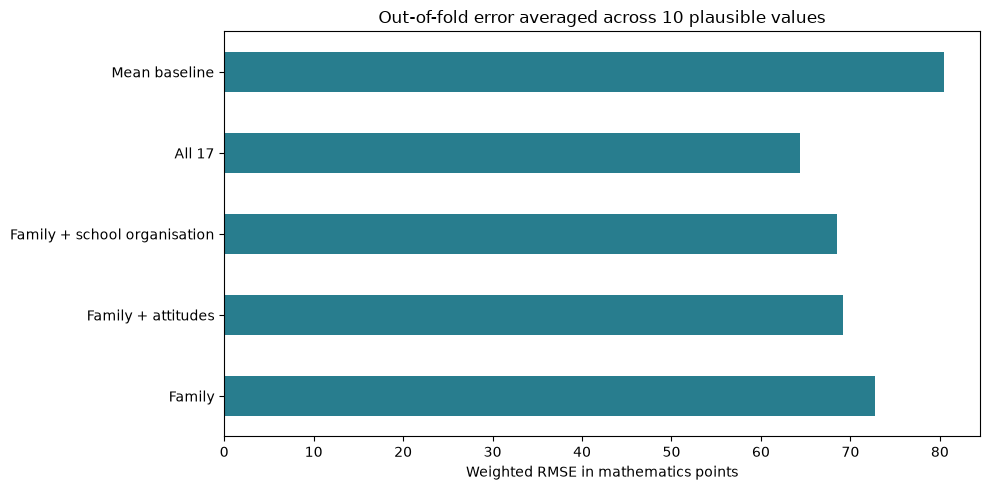

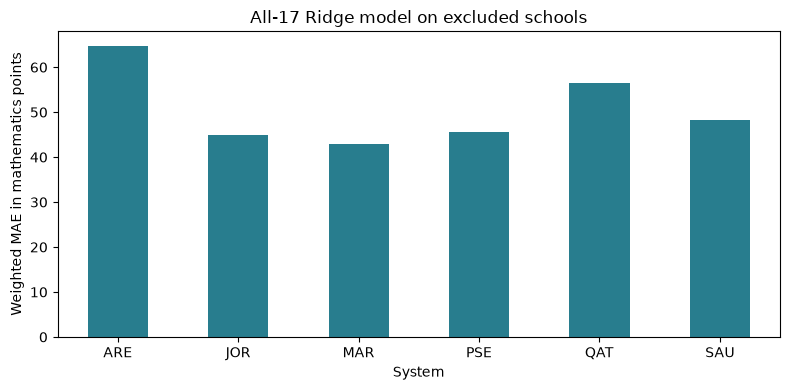

In [7]:
# Positive error reduction means the model improves over the family-only specification.
pooled = summary.xs("Pooled", level="system").copy()
comparison = pooled.loc[list(feature_sets)].copy()
comparison["RMSE_reduction_vs_family"] = pooled.loc["Family", "RMSE"] - comparison["RMSE"]
comparison["MAE_reduction_vs_family"] = pooled.loc["Family", "MAE"] - comparison["MAE"]
comparison["R2_increase_vs_family"] = comparison["R2"] - pooled.loc["Family", "R2"]
display(comparison.round(3))

# Compare pooled prediction errors with the weighted mean-score baseline.
fig, ax = plt.subplots(figsize=(10, 5))
pooled["RMSE"].plot.barh(ax=ax, color="#287D8E")
ax.set(xlabel="Weighted RMSE in mathematics points", ylabel="", title="Out-of-fold error averaged across 10 plausible values")
plt.tight_layout()
plt.show()
plt.close(fig)

# Compare system-specific errors for the primary model using the same metric.
fig, ax = plt.subplots(figsize=(8, 4))
summary.loc["All 17"].drop(index="Pooled")["MAE"].plot.bar(ax=ax, color="#287D8E", rot=0)
ax.set(xlabel="System", ylabel="Weighted MAE in mathematics points", title="All-17 Ridge model on excluded schools")
plt.tight_layout()
plt.show()
plt.close(fig)
print("Completed 5 school folds and all 10 PVs for every configuration.")

## 8. Baseline and predictor-group checks

The following tables quantify improvements on the same out-of-fold records. Positive reductions in RMSE and MAE indicate improvement. PV-specific consistency is a descriptive check, not ten independent replications or a significance test.

**In brief:** The mean-score baseline checks whether Ridge learns useful information beyond a simple prediction. The PV checks show whether improvements have a consistent direction across the ten targets.

In [8]:
# Quantify whether the full model improves over the weighted training-mean baseline.
baseline_check = pd.DataFrame({
    "mean_baseline": pooled.loc["Mean baseline", ["RMSE", "MAE", "R2"]],
    "full_Ridge": pooled.loc["All 17", ["RMSE", "MAE", "R2"]]
})
baseline_check["full_minus_baseline"] = baseline_check["full_Ridge"] - baseline_check["mean_baseline"]
# Negative error differences and positive R2 differences indicate improvement.
baseline_check["improves"] = baseline_check["full_minus_baseline"].mul([-1, -1, 1]).gt(0)
display(baseline_check.round(4))
print("Pooled RMSE reduction (%):", round(100 * (1 - pooled.loc["All 17", "RMSE"] / pooled.loc["Mean baseline", "RMSE"]), 2))

# Check whether the direction of each error improvement holds for every plausible value.
pooled_pv = metrics_by_pv.loc[metrics_by_pv["system"].eq("Pooled")]
rmse_by_pv = pooled_pv.pivot(index="PV", columns="configuration", values="RMSE")
improvement_by_pv = pd.DataFrame({
    "Full_vs_mean_baseline": rmse_by_pv["Mean baseline"] - rmse_by_pv["All 17"],
    "Attitudes_added_to_family": rmse_by_pv["Family"] - rmse_by_pv["Family + attitudes"],
    "School_org_added_to_family": rmse_by_pv["Family"] - rmse_by_pv["Family + school organisation"]
})
display(improvement_by_pv.agg(["mean", "min", "max"]).T.round(3))
display(improvement_by_pv.gt(0).sum().rename("PVs_with_lower_RMSE_out_of_10").to_frame())

# Compare each added group's improvement over family alone separately within systems.
system_comparison = summary.loc[["Family", "Family + attitudes", "Family + school organisation", "All 17"], "RMSE"].unstack("configuration")
for configuration in ["Family + attitudes", "Family + school organisation", "All 17"]:
    system_comparison[configuration + " RMSE_reduction_vs_family"] = system_comparison["Family"] - system_comparison[configuration]
display(system_comparison.round(3))

Pooled RMSE reduction (%): 20.04


,mean_baseline,full_Ridge,full_minus_baseline,improves
RMSE,80.4613,64.3335,-16.1277,True
MAE,62.7649,50.5141,-12.2507,True
R2,-0.0003,0.3605,0.3608,True


,mean,min,max
Full_vs_mean_baseline,16.128,15.994,16.272
Attitudes_added_to_family,3.546,3.435,3.656
School_org_added_to_family,4.259,4.175,4.354


,PVs_with_lower_RMSE_out_of_10
Full_vs_mean_baseline,10
Attitudes_added_to_family,10
School_org_added_to_family,10


configuration,Family,Family + attitudes,Family + school organisation,All 17,Family + attitudes RMSE_reduction_vs_family,Family + school organisation RMSE_reduction_vs_family,All 17 RMSE_reduction_vs_family
system,,,,,,,
Pooled,72.727,69.181,68.468,64.334,3.546,4.259,8.393
ARE,97.589,90.841,87.503,81.080,6.748,10.086,16.509
JOR,62.362,60.004,59.673,56.451,2.358,2.689,5.911
MAR,58.423,57.075,56.196,54.169,1.348,2.227,4.254
PSE,63.542,61.357,60.802,57.536,2.185,2.740,6.006
QAT,82.457,77.279,77.064,71.404,5.178,5.393,11.053
SAU,63.812,62.195,64.150,61.060,1.616,-0.338,2.752


## 9. System errors in the context of achievement spread

Absolute errors can be larger where outcome scores are more dispersed. Compare MAE and RMSE with weighted outcome SD, R² and a training-mean baseline. Weighted outcome SD is computed separately for each PV and then averaged. These ratios describe performance and do not establish fairness or explain the causes of system differences.

**In brief:** A system with a wider range of scores can have larger errors even when useful patterns are predicted. We therefore examine error alongside score spread, R² and the baseline.

In [9]:
# Calculate observed achievement spread without averaging individual PV scores.
spread_rows = []
for system in sorted(df["CNT"].unique()):
    selected = df["CNT"].eq(system)
    weights = df.loc[selected, "SENWT"]
    # NumPy summarises all ten PV columns independently along the student axis.
    values = df.loc[selected, targets].to_numpy()
    centre = np.average(values, axis=0, weights=weights)
    spread = np.sqrt(np.average((values - centre) ** 2, axis=0, weights=weights))
    spread_rows.append({"system": system, "outcome_SD": spread.mean()})
outcome_spread = pd.DataFrame(spread_rows).set_index("system")["outcome_SD"]
system_context = summary.loc["All 17"].drop(index="Pooled").join(outcome_spread)
system_context["RMSE_divided_by_SD"] = system_context["RMSE"] / system_context["outcome_SD"]
system_context["MAE_divided_by_SD"] = system_context["MAE"] / system_context["outcome_SD"]
system_context["baseline_RMSE"] = summary.loc["Mean baseline", "RMSE"].drop(index="Pooled")
system_context["RMSE_reduction_vs_baseline"] = system_context["baseline_RMSE"] - system_context["RMSE"]
display(system_context.round(3))

,RMSE,MAE,R2,outcome_SD,RMSE_divided_by_SD,MAE_divided_by_SD,baseline_RMSE,RMSE_reduction_vs_baseline
system,,,,,,,,
ARE,81.080,64.742,0.360,101.355,0.800,0.639,110.305,29.225
JOR,56.451,44.907,0.163,61.724,0.915,0.728,67.145,10.694
MAR,54.169,42.972,0.253,62.696,0.864,0.685,66.750,12.581
PSE,57.536,45.596,0.239,65.938,0.873,0.691,69.474,11.937
QAT,71.404,56.588,0.353,88.756,0.804,0.638,92.647,21.243
SAU,61.060,48.280,0.133,65.578,0.931,0.736,65.591,4.531


## 10. Alpha search boundaries

A selected boundary value is a diagnostic rather than proof of a poor model. Count lower- and upper-bound selections across the five outer training partitions. Any search extension must be separately recorded and tuned inside training schools. Do not enlarge the search in response to outer-test performance and then present it as an untouched evaluation.

**In brief:** If alpha repeatedly wins at an edge of the search range, a wider training-only search may be worth considering. A single boundary selection does not by itself require a new search.

In [10]:
# Identify selections at the smallest and largest alpha values searched.
alpha_review = tuning_results.copy()
alpha_review["lower_boundary"] = np.isclose(alpha_review["alpha"], alpha_grid.min())
alpha_review["upper_boundary"] = np.isclose(alpha_review["alpha"], alpha_grid.max())
boundary_summary = alpha_review.groupby("configuration").agg(
    outer_folds=("outer_fold", "size"),
    lower_boundary_count=("lower_boundary", "sum"),
    upper_boundary_count=("upper_boundary", "sum"),
    smallest_selected_alpha=("alpha", "min"),
    largest_selected_alpha=("alpha", "max")
)
boundary_summary["boundary_selected_in_multiple_folds"] = (
    boundary_summary["lower_boundary_count"] + boundary_summary["upper_boundary_count"]
).ge(2)
display(boundary_summary)
print("Search range:", alpha_grid.min(), "to", alpha_grid.max())
print("No search extension or outer-result-driven model selection was performed.")

Search range: 0.01 to 10000.0
No search extension or outer-result-driven model selection was performed.


,outer_folds,lower_boundary_count,upper_boundary_count,smallest_selected_alpha,largest_selected_alpha,boundary_selected_in_multiple_folds
configuration,,,,,,
All 17,5,1,0,0.01,10.0,False
Family,5,0,0,10.00,10.0,False
Family + attitudes,5,0,0,10.00,10.0,False
Family + school organisation,5,0,0,10.00,100.0,False


## 11. Uncertainty and handover checks

Conditional SE combines evaluation-weight variation and PV variation while predictions remain fixed. Between-fold SD instead describes variation across five school test partitions. Neither is an estimate of repeated-training variability under independent new samples. Measuring the latter requires an additional resampling and refitting experiment.

Share the notebook in 03_baselines on a new branch based on Ahmed-EDA. It loads that checkout's data/clean files and does not download files from GitHub. All predictions remain in memory and are not exported.

**In brief:** Conditional standard errors and differences between school folds describe different sources of variation. These final checks also confirm that the saved folds and student weights were preserved.

In [11]:
# Display the two uncertainty components for pooled primary-model performance.
display(uncertainty.loc[uncertainty["system"].eq("Pooled")].round(6))

# Describe fold variation separately without calling it a survey SE or training uncertainty.
full_fold_metrics = fold_metrics.loc[fold_metrics["configuration"].eq("All 17")].groupby("fold")[["RMSE", "MAE", "R2"]].mean()
fold_variation = full_fold_metrics.agg(["min", "max", "std"]).T.rename(columns={"std": "descriptive_fold_SD"})
display(fold_variation.round(4))
print("Retraining uncertainty: not estimated by this experiment.")

# Verify that modelling preserves school assignments and student weights.
assert np.all(visits == 1)
assert df.groupby(keys)["fold"].nunique().eq(1).all()
pd.testing.assert_series_equal(df["SENWT"], weight_snapshot)
print("Handover checks passed: student weights unchanged, school folds preserved, one excluded-school prediction per student and PV.")

Retraining uncertainty: not estimated by this experiment.
Handover checks passed: student weights unchanged, school folds preserved, one excluded-school prediction per student and PV.


,system,metric,estimate,conditional_SE,within_PV_BRR_variance,between_PV_variance
0,Pooled,RMSE,64.333548,0.379089,0.087996,0.050648
1,Pooled,MAE,50.514124,0.323966,0.065498,0.035869
2,Pooled,R2,0.360524,0.006605,0.000041,0.000003


,min,max,descriptive_fold_SD
RMSE,63.8261,65.0391,0.4574
MAE,50.1180,51.1963,0.4419
R2,0.3172,0.3837,0.0255


## 12. Regularisation experiment

The table and plots use PV1 training and validation results saved by GridSearchCV. They show how error changes across alpha values. Each RMSE is the square root of the mean inner-fold MSE, rather than the arithmetic mean of fold RMSEs.

The outer-fold results remain separate. No new settings are selected from this plot.

**In brief:** The plots compare performance on training and validation records as alpha changes. Nearly flat curves indicate little sensitivity to alpha, while rising errors in both panels at very large alpha indicate underfitting.

,outer_fold,alpha,training_RMSE,validation_RMSE,validation_minus_training_RMSE
21,0,0.01,64.1207,64.4051,0.2844
22,0,0.10,64.1207,64.4051,0.2844
23,0,1.00,64.1207,64.4053,0.2846
24,0,10.00,64.1214,64.4053,0.2839
25,0,100.00,64.1482,64.4096,0.2613
26,0,1000.00,64.4453,64.6425,0.1972
27,0,10000.00,66.0228,66.1392,0.1165
49,1,0.01,64.2977,64.6724,0.3747
50,1,0.10,64.2977,64.6701,0.3724
51,1,1.00,64.2977,64.6557,0.3580


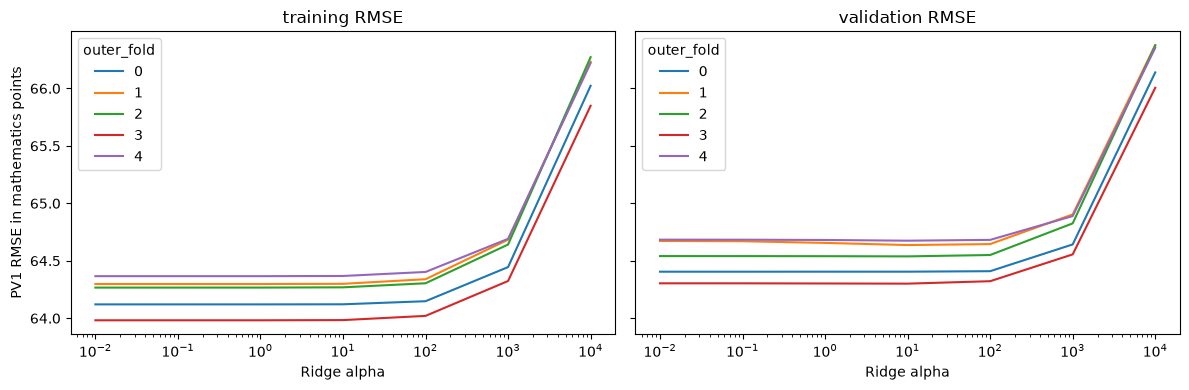

In [12]:
# Use GridSearchCV's saved results rather than implementing another training experiment.
alpha_curve = alpha_search_results.rename(columns={"param_ridge__alpha": "alpha"}).copy()
alpha_curve["training_RMSE"] = np.sqrt(-alpha_curve["mean_train_score"])
alpha_curve["validation_RMSE"] = np.sqrt(-alpha_curve["mean_test_score"])
alpha_curve["validation_minus_training_RMSE"] = alpha_curve["validation_RMSE"] - alpha_curve["training_RMSE"]

# Show the primary model's error for every alpha and outer training partition.
primary_curve = alpha_curve.loc[alpha_curve["configuration"].eq("All 17")]
display(primary_curve[["outer_fold", "alpha", "training_RMSE", "validation_RMSE", "validation_minus_training_RMSE"]].round(4))

# Plot inner error curves for each partition without reusing outer test outcomes for tuning.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for column, ax in zip(["training_RMSE", "validation_RMSE"], axes):
    primary_curve.pivot(index="alpha", columns="outer_fold", values=column).plot(ax=ax, logx=True)
    ax.set(xlabel="Ridge alpha", ylabel="PV1 RMSE in mathematics points", title=column.replace("_", " "))
plt.tight_layout()
plt.show()
plt.close(fig)